
# Introduccion al Proyecto: Predicción de Abandono de Clientes — Beta Bank

## Contexto del Problema
El Banco Beta Bank enfrenta una situación importante: los clientes se están yendo cada mes poco a poco y los banqueros descubrieron que es más barato salvar a los clientes existentes que atraer nuevos. Para esto, el banco necesita un sistema que le ayude a detectar si los clientes dejarán el banco pronto, para ofrecerles una opción que genere la lealtad.

## Objetivo del Proyecto
Predecir si un cliente dejará el banco, mediante un modelo de Machine Learning, basándose en patrones de abandono y término de contratos con el banco de clientes que se han ido en el pasado. El modelo se realizará maximizando el valor F1 (mínimo requerido: 0.59).
Se evaluará también la métrica AUC-ROC.

## Datos Disponibles
Trabajaremos en un data set que contiene información del comportamiento pasado de los clientes y la terminación de contratos con el banco. Las variables incluyen:

* **RowNumber:** índice de cadena de datos
* **CustomerId:** identificador de cliente único
* **Surname:** apellido
* **CreditScore:** valor de crédito
* **Geography:** país de residencia
* **Gender:** sexo
* **Age:** edad
* **Tenure:** período durante el cual ha madurado el depósito a plazo fijo de un cliente (años)
* **Balance:** saldo de la cuenta
* **NumOfProducts:** número de productos bancarios utilizados por el cliente
* **HasCrCard:** el cliente tiene una tarjeta de crédito (1 - sí; 0 - no)
* **IsActiveMember:** actividad del cliente (1 - sí; 0 - no)
* **EstimatedSalary:** salario estimado
* **Exited**: Variable objetivo. El cliente se ha ido (1 - sí; 0 - no)

## Metodología
1. Exploración, análisis y preparación de los datos de comportamiento.
2. Analisis de equilibrio de clases y creación de un modelo base.
3. Mejora del modelo corrigiendo el desequilibrio usando técnicas diferentes y seleccionando el que mejor resultado tenga en F1.
4. Validacion final del modelo para confirmar que realmente funciona bien 


## Paso 1: Preparación de los Datos

### 1.1 Importación de librerías

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, recall_score, f1_score, roc_auc_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder


### 1.2 Carga del dataset

In [2]:
#cargar los datos
df = pd.read_csv('/datasets/Churn.csv', sep=',', encoding='utf-8', quotechar= '"')

#información general
print("Información general del Data Frame:")
print(df.info())

Información general del Data Frame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), object(3)
memory usage: 1.1+ MB
None


### 1.3 Exploración inicial (shape, tipos, valores nulos)

In [3]:
print(f"Forma del DataFrame: {df.shape}")
print(f"Valores faltantes por columna:")
print(df.isnull().sum())
print()
print("Vista del DataFrame:")
display(df)

Forma del DataFrame: (10000, 14)
Valores faltantes por columna:
RowNumber            0
CustomerId           0
Surname              0
CreditScore          0
Geography            0
Gender               0
Age                  0
Tenure             909
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
dtype: int64

Vista del DataFrame:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8.0,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1.0,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2.0,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5.0,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10.0,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7.0,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3.0,75075.31,2,1,0,92888.52,1




### Observaciones Iniciales
#### Estructura del Dataset
- **Tamaño**: 10,000 clientes con 14 columnas
- **Calidad**: 909 valores faltantes en la variable Tenure
#### Variables del Dataset
- **Variables numéricas**: `RowNumber`, `CustomerId`, `CreditScore`, `Age`, `Tenure`, `Balance`, `NumOfProducts`, `HasCrCard`, `IsActiveMember`, `EstimatedSalary`
- **Variables categóricas**: `Surname`, `Geography`, `Gender`
- **Variable Objetivo**: Exited (0 = no, 1 = Si)
#### Observación preliminar
- En la muestra visible, la mitad de clientes han abandonado el banco y la otra mitad continua inscrita.

### 1.4 Preprocesamiento

In [4]:
#Eliminar columnas irrelevantes que no aportan información útil para predecir si un cliente se va o no
df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1, inplace=True)
print(f"Forma del DataFrame después de eliminar columnas irrelevantes:")
print(df.shape)


Forma del DataFrame después de eliminar columnas irrelevantes:
(10000, 11)


In [5]:
#tratar valores ausentes
print(f"Valores faltantes por columna:")
print(df.isnull().sum())
print()
print("Columna 'Tenure':")
display(df[df['Tenure'].isna()])
print()
print
print(f"Mediana:", df['Tenure'].median())
print(f"Media:", df['Tenure'].mean())
#comparar estadísticas en filas donde la columna 'Tenure' son NaN con filas donde 'Tenure' no son NaN
con_nan = df[df['Tenure'].isna()]
no_nan = df[df['Tenure'].notna()]
print()
print("Grupo CON valores faltantes en Tenure:")
print(df[df['Tenure'].isnull()].describe())
print()
print("\nGrupo SIN valores faltantes en Tenure:")
print(df[df['Tenure'].notnull()].describe())
print()
#agregar al filtro la variable Objetivo 'Exited' para comparación adicional
print(df[df['Tenure'].isna()]['Exited'].value_counts(normalize=True))
print(df[df['Tenure'].notna()]['Exited'].value_counts(normalize=True))
print()
#reemplazar los valores Nan de 'Tenure' con la Mediana
df['Tenure'].fillna(df['Tenure'].median(), inplace=True)
print(f"Valores faltantes por columna:")
print(df.isnull().sum())


Valores faltantes por columna:
CreditScore          0
Geography            0
Gender               0
Age                  0
Tenure             909
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
dtype: int64

Columna 'Tenure':


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
30,591,Spain,Female,39,NaN,0.00,3,1,0,140469.38,1
48,550,Germany,Male,38,NaN,103391.38,1,0,1,90878.13,0
51,585,Germany,Male,36,NaN,146050.97,2,0,0,86424.57,0
53,655,Germany,Male,41,NaN,125561.97,1,0,0,164040.94,1
60,742,Germany,Male,35,NaN,136857.00,1,0,0,84509.57,0
...,...,...,...,...,...,...,...,...,...,...,...
9944,744,Germany,Male,41,NaN,190409.34,2,1,1,138361.48,0
9956,520,France,Female,46,NaN,85216.61,1,1,0,117369.52,1
9964,479,France,Male,34,NaN,117593.48,2,0,0,113308.29,0
9985,659,France,Male,36,NaN,123841.49,2,1,0,96833.00,0



Mediana: 5.0
Media: 4.997690023099769

Grupo CON valores faltantes en Tenure:
       CreditScore         Age  Tenure        Balance  NumOfProducts  \
count   909.000000  909.000000     0.0     909.000000     909.000000   
mean    648.451045   38.647965     NaN   76117.341474       1.530253   
std      99.079381    9.785438     NaN   63105.690715       0.588452   
min     359.000000   18.000000     NaN       0.000000       1.000000   
25%     580.000000   32.000000     NaN       0.000000       1.000000   
50%     647.000000   37.000000     NaN   96674.550000       1.000000   
75%     718.000000   43.000000     NaN  128554.980000       2.000000   
max     850.000000   92.000000     NaN  206663.750000       4.000000   

        HasCrCard  IsActiveMember  EstimatedSalary      Exited  
count  909.000000      909.000000       909.000000  909.000000  
mean     0.710671        0.510451     99180.389373    0.201320  
std      0.453701        0.500166     56378.063765    0.401207  
min      0.0

In [6]:
#Codificar variables categóricas

#Conteo de valores unicos por columna categórica para mayor referencia
display(df['Geography'].value_counts(normalize=True, dropna=False))
print()
display(df['Gender'].value_counts(normalize=True, dropna=False))
print()
#implementar OneHotEncoder
encoder = OneHotEncoder(sparse=False, drop='first')
encoded_data = encoder.fit_transform(df[['Geography', 'Gender']])
encoded_df = pd.DataFrame(encoded_data, columns=encoder.get_feature_names(['Geography', 'Gender']))
df = pd.concat([df.drop(['Geography', 'Gender'], axis=1), encoded_df], axis=1)
display(df.head())


France     0.5014
Germany    0.2509
Spain      0.2477
Name: Geography, dtype: float64

Male      0.5457
Female    0.4543
Name: Gender, dtype: float64

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2.0,0.00,1,1,1,101348.88,1,0.0,0.0,0.0
1,608,41,1.0,83807.86,1,0,1,112542.58,0,0.0,1.0,0.0
2,502,42,8.0,159660.80,3,1,0,113931.57,1,0.0,0.0,0.0
3,699,39,1.0,0.00,2,0,0,93826.63,0,0.0,0.0,0.0
4,850,43,2.0,125510.82,1,1,1,79084.10,0,0.0,1.0,0.0


In [7]:
# Escalar características numéricas

cols_to_scale = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

scaler = StandardScaler()
df[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

display(df.head())


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,-0.326221,0.293517,-1.086246,-1.225848,-0.911583,1,1,0.021886,1,0.0,0.0,0.0
1,-0.440036,0.198164,-1.448581,0.117350,-0.911583,0,1,0.216534,0,0.0,1.0,0.0
2,-1.536794,0.293517,1.087768,1.333053,2.527057,1,0,0.240687,1,0.0,0.0,0.0
3,0.501521,0.007457,-1.448581,-1.225848,0.807737,0,0,-0.108918,0,0.0,0.0,0.0
4,2.063884,0.388871,-1.086246,0.785728,-0.911583,1,1,-0.365276,0,0.0,1.0,0.0


##  Conclusiones - Preprocesamiento

- Se eliminaron las columnas `RowNumber`, `CustomerId` y `Surname` por ser irrelevantes para el modelo.
- Los valores nulos en `Tenure` (909 registros) se imputaron con la **mediana (5.0)** para evitar distorsiones por outliers.
- Las variables categóricas `Geography` y `Gender` se codificaron con **OneHotEncoder** usando `drop='first'` para evitar multicolinealidad.
- Las variables numéricas continuas se estandarizaron con **StandardScaler**, dejando todas las columnas en la misma escala para el modelo.

## Paso 2: Equilibrio de Clases y Modelo Base

En este paso analizaremos si las clases de la variable objetivo `Exited` están balanceadas,
ya que un desequilibrio puede sesgar las predicciones del modelo hacia la clase mayoritaria.

A continuación:
- Visualizaremos la distribución de clases (clientes que se fueron vs. los que se quedaron).
- Dividiremos los datos en conjuntos de entrenamiento, validación y prueba.
- Entrenaremos un modelo base **sin corregir** el desequilibrio para establecer un punto de referencia.
- Evaluaremos su desempeño con las métricas **F1** y **AUC-ROC**.

### 2.1 Análisis del equilibrio de clases

In [8]:

# Analizar si las clases de 'Exited' estan balanceadas
# Distribución de los registros por clase en la variable objetivo
print("=== DISTRIBUCION DE LA VARIABLE OBJETIVO ('Exited') ===")
print()

#Conteo de Valores
print("Conteo de clientes(0) y exclientes(1)")
print(len(df['Exited']))
print(df['Exited'].value_counts().sort_index())
print()

#Porcentajes
print("Distribución porcentual:")
print(df['Exited'].value_counts(normalize=True).sort_index() * 100)
print()

#Estadisticas basicas de la variable objetivo
print("Estadisticas básicas de 'Exited':")
print(df['Exited'].describe())



=== DISTRIBUCION DE LA VARIABLE OBJETIVO ('Exited') ===

Conteo de clientes(0) y exclientes(1)
10000
0    7963
1    2037
Name: Exited, dtype: int64

Distribución porcentual:
0    79.63
1    20.37
Name: Exited, dtype: float64

Estadisticas básicas de 'Exited':
count    10000.000000
mean         0.203700
std          0.402769
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: Exited, dtype: float64


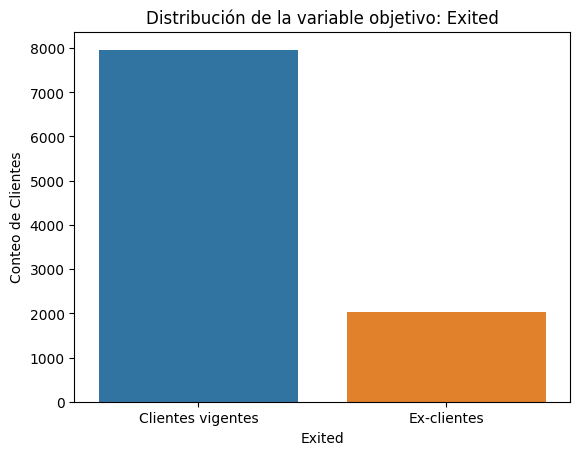

In [9]:
#Visualización Gráfica de la distribución de la variable objetivo

sns.countplot(x='Exited', data=df)
plt.title('Distribución de la variable objetivo: Exited')
plt.xticks([0, 1], ['Clientes vigentes', 'Ex-clientes'])
plt.ylabel ('Conteo de Clientes')
plt.show()

## Observaciones de analisis de variable objetivo
**Distrubución encontrada**:
* **Registros totales**: 10000 clientes de los cuales:
* **Clientes existentes**: 7,963 (79.63%)
* **Exclientes**: 2037 (20.37%)
  
**Intepretacion**:
* Es un data set desbalanceado en proporción 79.63-20.37
* La mayoría de los clientes (7,963) continúan dentro del sistema del banco por lo que la atención debe enfocarse en los patrones de comportamiento de los que ya se fueron (2037) para identificar a los clientes actuales que están en riesgo de irse.
* Los 2037 registros de exclientes son suficientes para entrenar el modelo con la clase positiva.
  
**Implicaciones para el modelo**:
* Desbalance no extremo, pero deberá monitorearse.
* El modelo que siempre prediga que el cliente se queda tendría n 79.63% de precisión.
* Nuestro modelo deberá superar este baseline.
* Es posible que se requiera considar técnicas de balanceo si el rendimiento es bajo.


### 2.2 División de los datos (entrenamiento / validación / prueba)


**División de datos**

Los datos se dividirán en 3 conjuntos con `train_test_split`de la siguiente manera:
+ **Entrenamiento (60%)** -> para entrenar el modelo
+ **Validación (20%)** -> para ajustar parámetros
+ **Prueba (20%)** -> para la evaluación final.


In [10]:
# Definir características (features) y variable objetivo (target)
features = df.drop('Exited', axis=1)  # Todas las columnas excepto 'Exited'
target = df['Exited']  # Solo la columna 'Exited'

# Primera división: 60% entrenamiento, 40% temporal
features_train, features_temp, target_train, target_temp = train_test_split(features, target, test_size=0.4, random_state=12345)

# Segunda división: del 40% temporal, hacer 20% validación y 20% prueba
features_valid, features_test, target_valid, target_test = train_test_split(features_temp, target_temp, test_size=0.5, random_state=12345)

# Verificar los tamaños de los conjuntos
print("Tamaños de los conjuntos:")
print(f"Conjunto original: {len(df)} muestras")
print(f"Entrenamiento: {len(features_train)} muestras ({len(features_train)/len(df)*100:.1f}%)")
print(f"Validación: {len(features_valid)} muestras ({len(features_valid)/len(df)*100:.1f}%)")
print(f"Prueba: {len(features_test)} muestras ({len(features_test)/len(df)*100:.1f}%)")

# Verificar que las formas coincidan
print("\nFormas de los conjuntos:")
print(f"features_train: {features_train.shape}, target_train: {target_train.shape}")
print(f"features_valid: {features_valid.shape}, target_valid: {target_valid.shape}")
print(f"features_test: {features_test.shape}, target_test: {target_test.shape}")

Tamaños de los conjuntos:
Conjunto original: 10000 muestras
Entrenamiento: 6000 muestras (60.0%)
Validación: 2000 muestras (20.0%)
Prueba: 2000 muestras (20.0%)

Formas de los conjuntos:
features_train: (6000, 11), target_train: (6000,)
features_valid: (2000, 11), target_valid: (2000,)
features_test: (2000, 11), target_test: (2000,)


### 2.3 Entrenamiento del modelo base (sin corregir desequilibrio)

In [11]:
# El modelo base será Decision Tree
print("=== MODELO BASE===")
# Crear el modelo 
model = DecisionTreeClassifier(random_state=12345)

# Entrenar el modelo
model.fit(features_train, target_train)

# Hacer predicciones en el conjunto de validación
predictions_valid = model.predict(features_valid)

# Calcular la exactitud
accuracy = accuracy_score(target_valid, predictions_valid)

print(f"Exactitud en validación: {accuracy:.4f}")

=== MODELO BASE===
Exactitud en validación: 0.7945


### 2.4 Evaluación del modelo base (F1 y AUC-ROC)

In [12]:
#Evaluación del modelo base F1_score
f1 = f1_score(target_valid, predictions_valid)
print(f"F1 Score: {f1:.4f}")

#Evaluación del modelo base  AUC-ROC
auc_roc = roc_auc_score(target_valid, predictions_valid)
print(f"AUC-ROC: {auc_roc:.4f}")

F1 Score: 0.5030
AUC-ROC: 0.6853


### 2.5 Conclusiones del modelo base


### Resultados Obtenidos

+ **Exactitud en conjunto de validación 0.7945 (79.45%)**: De cada 100 clientes el modelo acierta en 79, pero recordemos que el 79.63% de los clientes se quedan, y este modelo podría simplemente decir "nadie se va" y tener esa misma exactitud, pero eso no es suficiente.
+ **F1 Score(.5030)**: Mide qué tan bien detecta específicamente a los clientes que si se van combinando cuántos clientes en riesto se detecto y cuántas de esas alertas fueron correctas. Un valor de 0.50 significa que el modelo apenas acierta la mitad de las veces en detectar abandonos. El mínimo requerido es 0.59, así que no cumple.
+ **AUC-ROC (0.6853)**: Mide qué tan bien el modelo distingue entre "se va" y "se queda". Va de 0.5 (azar) a 1.0 (perfecto. Un 0.68 es mejor que el azar, pero todavía hay mucho margen de mejora.

El modelo tiene este rendimiento por el desequilibrio de las clases (79.63-20.37).

Para mejorarlo, haremos la corrección del Desequilibrio en el próximo paso.

## Paso 3: Mejora del Modelo — Corrección del Desequilibrio

En este paso aplicaremos técnicas para corregir el desequilibrio de clases (79.63% vs 20.37%)
identificado en el Paso 2, con el objetivo de mejorar el F1 Score por encima del mínimo requerido de 0.59.
A continuación:
- Entrenaremos un modelo con **ajuste de pesos de clase** (class_weight='balanced').
- Aplicaremos técnicas de **sobremuestreo (Upsampling)** o **submuestreo (Downsampling)**.
- Compararemos los resultados de ambas técnicas y seleccionaremos el mejor modelo.

### 3.1 Técnica 1: Ajuste de pesos de clase (class_weight)

#### 3.1.1. DecisionTree class_weight

In [13]:
# Entrenar el modelo con class_weight
print("=== MODELO CON AJUSTE DE PESOS DE CLASE ===")
model_balanced_dt = DecisionTreeClassifier(random_state=12345, class_weight='balanced')
model_balanced_dt.fit(features_train, target_train)
display(model_balanced_dt.get_params())
predictions_valid_balanced_dt = model_balanced_dt.predict(features_valid)
print()
print("=== PREDICCIONES EN EL CONJUNTO DE VALIDACIÓN ===")
dt_acc_cw = accuracy_score(target_valid, predictions_valid_balanced_dt)
print(f"Precisión del modelo (DT, CW): {dt_acc_cw:.4f}")
dt_f1_cw = f1_score(target_valid, predictions_valid_balanced_dt)
print(f"F1 Score (DT, CW): {dt_f1_cw:.4f}")
probabilities_dt_cw = model_balanced_dt.predict_proba(features_valid)[:,1]
dt_auc_cw = roc_auc_score(target_valid, probabilities_dt_cw)
print(f"AUC-ROC (DT, CW): {dt_auc_cw:.4f}")

=== MODELO CON AJUSTE DE PESOS DE CLASE ===


{'ccp_alpha': 0.0,
 'class_weight': 'balanced',
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_impurity_split': None,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'random_state': 12345,
 'splitter': 'best'}


=== PREDICCIONES EN EL CONJUNTO DE VALIDACIÓN ===
Precisión del modelo (DT, CW): 0.7825
F1 Score (DT, CW): 0.4765
AUC-ROC (DT, CW): 0.6689


#### 3.1.2. Modelo RandomForestClassifier class_weight

In [14]:
# Entrenar el modelo con class_weight
print("=== MODELO CON AJUSTE DE PESOS DE CLASE ===")
model_balanced_rf = RandomForestClassifier(random_state=12345, class_weight='balanced')
model_balanced_rf.fit(features_train, target_train)
display(model_balanced_rf.get_params())
predictions_valid_balanced_rf = model_balanced_rf.predict(features_valid)
print()
print("=== PREDICCIONES EN EL CONJUNTO DE VALIDACIÓN ===")
rf_acc_cw = accuracy_score(target_valid, predictions_valid_balanced_rf)
print(f"Precisión del modelo (RF, CW): {rf_acc_cw:.4f}")
rf_f1_cw = f1_score(target_valid, predictions_valid_balanced_rf)
print(f"F1 Score (RF, CW): {rf_f1_cw:.4f}")
probabilities_rf_cw = model_balanced_rf.predict_proba(features_valid)[:,1]
rf_auc_cw = roc_auc_score(target_valid, probabilities_rf_cw)
print(f"AUC-ROC (RF, CW): {rf_auc_cw:.4f}")

=== MODELO CON AJUSTE DE PESOS DE CLASE ===


{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': 'balanced',
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'auto',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_impurity_split': None,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 12345,
 'verbose': 0,
 'warm_start': False}


=== PREDICCIONES EN EL CONJUNTO DE VALIDACIÓN ===
Precisión del modelo (RF, CW): 0.8585
F1 Score (RF, CW): 0.5653
AUC-ROC (RF, CW): 0.8387


#### 3.1.3. LogisticRegression class_weight

In [15]:
#Entrenar el modelo LogisticRegression con class_weigth
print("=== MODELO CON AJUSTE DE PESOS DE CLASE ===")
model_balanced_lr = LogisticRegression(random_state=12345, class_weight='balanced')
model_balanced_lr.fit(features_train, target_train)
display(model_balanced_lr.get_params())
predictions_valid_balanced_lr = model_balanced_lr.predict(features_valid)
print("=== PREDICCIONES EN EL CONJUNTO DE VALIDACIÓN ===")
lr_acc_cw = accuracy_score(target_valid, predictions_valid_balanced_lr)
print(f"Precisión del modelo (LR, CW): {lr_acc_cw:.4f}")
lr_f1_cw = f1_score(target_valid, predictions_valid_balanced_lr)
print(f"F1 Score (LR, CW): {lr_f1_cw:.4f}")
probabilities_lr_cw = model_balanced_lr.predict_proba(features_valid)[:,1]
lr_auc_cw = roc_auc_score(target_valid, probabilities_lr_cw)
print(f"AUC-ROC (LR, CW): {lr_auc_cw:.4f}")

=== MODELO CON AJUSTE DE PESOS DE CLASE ===


{'C': 1.0,
 'class_weight': 'balanced',
 'dual': False,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'l1_ratio': None,
 'max_iter': 100,
 'multi_class': 'auto',
 'n_jobs': None,
 'penalty': 'l2',
 'random_state': 12345,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'verbose': 0,
 'warm_start': False}

=== PREDICCIONES EN EL CONJUNTO DE VALIDACIÓN ===
Precisión del modelo (LR, CW): 0.7020
F1 Score (LR, CW): 0.4889
AUC-ROC (LR, CW): 0.7637


### 3.2 Técnica 2: Sobremuestreo (Upsampling) y Submuestreo (Downsampling)

#### 3.2.1. DecisionTreeClassifier Upsampling

In [16]:
import pandas as pd
from sklearn.utils import shuffle

#Entrenar modelo Sobremuestreo (Unsampling)
print("=== MODELO CON SOBREMUESTREO ===")
#Función upsample
def upsample(features, target, repeat):
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    target_zeros = target[target == 0]
    target_ones = target[target == 1]

    features_upsampled = pd.concat([features_zeros] + [features_ones] * repeat)
    target_upsampled = pd.concat([target_zeros] + [target_ones] * repeat)

    features_upsampled, target_upsampled = shuffle(features_upsampled, target_upsampled, random_state=12345)

    return features_upsampled, target_upsampled

features_upsampled = features_train # Uso de una variable común para la técnica
target_upsampled = target_train # Uso de una variable común para la técnica
features_upsampled, target_upsampled = upsample(features_upsampled, target_upsampled, 4)

model_upsampled_dt = DecisionTreeClassifier(random_state=12345)
model_upsampled_dt.fit(features_upsampled, target_upsampled)
predictions_valid_upsampled_dt = model_upsampled_dt.predict(features_valid)

print("=== Predicciones en el conjunto de validación ===")
dt_acc_up = accuracy_score(target_valid, predictions_valid_upsampled_dt)
print(f"Precisión del modelo (DT, Up): {dt_acc_up:.4f}")
dt_f1_up = f1_score(target_valid, predictions_valid_upsampled_dt)
print(f"F1 Score (DT, Up): {dt_f1_up:.4f}")
probabilities_dt_up = model_upsampled_dt.predict_proba(features_valid)[:,1]
dt_auc_up = roc_auc_score(target_valid, probabilities_dt_up)
print(f"AUC-ROC (DT, Up): {dt_auc_up:.4f}")

=== MODELO CON SOBREMUESTREO ===
=== Predicciones en el conjunto de validación ===
Precisión del modelo (DT, Up): 0.7890
F1 Score (DT, Up): 0.4903
AUC-ROC (DT, Up): 0.6774


#### 3 .2.2. RandomForest Upsampling

In [17]:
#Entrenar modelo Sobremuestreo (Upsampling)
print("=== MODELO CON SOBREMUESTREO ===")
#Reusamos función de la celda anterior para aplicar upsamplig
model_upsampled_rf = RandomForestClassifier(random_state=12345)
model_upsampled_rf.fit(features_upsampled, target_upsampled)
predictions_valid_upsampled_rf = model_upsampled_rf.predict(features_valid)

print("=== Predicciones en el conjunto de validación ===")
rf_acc_up = accuracy_score(target_valid, predictions_valid_upsampled_rf)
print(f"Precisión del modelo (RF, Up): {rf_acc_up:.4f}")
rf_f1_up = f1_score(target_valid, predictions_valid_upsampled_rf)
print(f"F1 Score (RF, Up): {rf_f1_up:.4f}")
probabilities_rf_up = model_upsampled_rf.predict_proba(features_valid)[:,1]
rf_auc_up = roc_auc_score(target_valid, probabilities_rf_up)
print(f"AUC-ROC (RF, Up): {rf_auc_up:.4f}")

=== MODELO CON SOBREMUESTREO ===
=== Predicciones en el conjunto de validación ===
Precisión del modelo (RF, Up): 0.8500
F1 Score (RF, Up): 0.6053
AUC-ROC (RF, Up): 0.8389


#### 3.2.3. LogisticRegression Upsampling

In [18]:
#Entrenar modelo Sobremuestreo (Unsampling)
print("=== MODELO CON SOBREMUESTREO ===")
# Reuso de función de upsampling 
model_upsampled_lr = LogisticRegression(random_state=12345)
model_upsampled_lr.fit(features_upsampled, target_upsampled)
predictions_valid_upsampled_lr = model_upsampled_lr.predict(features_valid)

print("=== Predicciones en el conjunto de validación ===")
lr_acc_up = accuracy_score(target_valid, predictions_valid_upsampled_lr)
print(f"Precisión del modelo (LR, Up): {lr_acc_up:.4f}")
lr_f1_up = f1_score(target_valid, predictions_valid_upsampled_lr)
print(f"F1 Score (LR, Up): {lr_f1_up:.4f}")
probabilities_lr_up = model_upsampled_lr.predict_proba(features_valid)[:,1]
lr_auc_up = roc_auc_score(target_valid, probabilities_lr_up)
print(f"AUC-ROC (LR, Up): {lr_auc_up:.4f}")

=== MODELO CON SOBREMUESTREO ===
=== Predicciones en el conjunto de validación ===
Precisión del modelo (LR, Up): 0.7020
F1 Score (LR, Up): 0.4889
AUC-ROC (LR, Up): 0.7636


#### 3.2.4. DecisionTreeClassifier Downsampling

In [19]:
# Downsampling
print("=== MODELO CON SUBMUESTREO ===")
#Función downsampling
def downsample(features, target, fraction):
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    target_zeros = target[target == 0]
    target_ones = target[target == 1]

    features_downsampled = pd.concat([features_zeros.sample(frac=fraction, random_state=12345)] + [features_ones])
    target_downsampled = pd.concat([target_zeros.sample(frac=fraction, random_state=12345)] + [target_ones])

    features_downsampled, target_downsampled = shuffle(features_downsampled, target_downsampled, random_state=12345)
    return features_downsampled, target_downsampled

features_downsampled = features_train 
target_downsampled = target_train 
features_downsampled, target_downsampled = downsample(features_downsampled, target_downsampled, 0.25)

model_downsampled_dt = DecisionTreeClassifier(random_state=12345)
model_downsampled_dt.fit(features_downsampled, target_downsampled)
predictions_valid_downsampled_dt = model_downsampled_dt.predict(features_valid)

print("=== Predicciones en el conjunto de validación ===")
dt_acc_ds = accuracy_score(target_valid, predictions_valid_downsampled_dt)
print(f"Precisión del modelo (DT, DS): {dt_acc_ds:.4f}")
dt_f1_ds = f1_score(target_valid, predictions_valid_downsampled_dt)
print(f"F1 Score (DT, DS): {dt_f1_ds:.4f}")
probabilities_dt_ds = model_downsampled_dt.predict_proba(features_valid)[:,1]
dt_auc_ds = roc_auc_score(target_valid, probabilities_dt_ds)
print(f"AUC-ROC (DT, DS): {dt_auc_ds:.4f}")

=== MODELO CON SUBMUESTREO ===
=== Predicciones en el conjunto de validación ===
Precisión del modelo (DT, DS): 0.6935
F1 Score (DT, DS): 0.4879
AUC-ROC (DT, DS): 0.6954


#### 3.2.5. RandomForest Downsampling

In [20]:
#Entrenar modelo Downsampling
print("=== MODELO CON SUBMUESTREO ===")
# Reuso de función Downsampling 
model_downsampled_rf = RandomForestClassifier(random_state=12345)
model_downsampled_rf.fit(features_downsampled, target_downsampled)
predictions_valid_downsampled_rf = model_downsampled_rf.predict(features_valid)

print("=== Predicciones en el conjunto de validación ===")
rf_acc_ds = accuracy_score(target_valid, predictions_valid_downsampled_rf)
print(f"Precisión del modelo (RF, DS): {rf_acc_ds:.4f}")
rf_f1_ds = f1_score(target_valid, predictions_valid_downsampled_rf)
print(f"F1 Score (RF, DS): {rf_f1_ds:.4f}")
probabilities_rf_ds = model_downsampled_rf.predict_proba(features_valid)[:,1]
rf_auc_ds = roc_auc_score(target_valid, probabilities_rf_ds)
print(f"AUC-ROC (RF, DS): {rf_auc_ds:.4f}")

=== MODELO CON SUBMUESTREO ===
=== Predicciones en el conjunto de validación ===
Precisión del modelo (RF, DS): 0.7700
F1 Score (RF, DS): 0.5725
AUC-ROC (RF, DS): 0.8451


#### 3.2.6. LogisticRegression Downsampling

In [21]:

#Entrenar al modelo con Downsampling
print("=== MODELO CON SUBMUESTREO ===")
# Reuso de función  Downsampling 
model_downsampled_lr = LogisticRegression(random_state=12345)
model_downsampled_lr.fit(features_downsampled, target_downsampled)
predictions_valid_downsampled_lr = model_downsampled_lr.predict(features_valid)

print("=== Predicciones en el conjunto de validación ===")
lr_acc_ds = accuracy_score(target_valid, predictions_valid_downsampled_lr)
print(f"Precisión del modelo (LR, DS): {lr_acc_ds:.4f}")
lr_f1_ds = f1_score(target_valid, predictions_valid_downsampled_lr)
print(f"F1 Score (LR, DS): {lr_f1_ds:.4f}")
probabilities_lr_ds = model_downsampled_lr.predict_proba(features_valid)[:,1]
lr_auc_ds = roc_auc_score(target_valid, probabilities_lr_ds)
print(f"AUC-ROC (LR, DS): {lr_auc_ds:.4f}")

=== MODELO CON SUBMUESTREO ===
=== Predicciones en el conjunto de validación ===
Precisión del modelo (LR, DS): 0.7005
F1 Score (LR, DS): 0.4841
AUC-ROC (LR, DS): 0.7622


### 3.3 Comparación de modelos y selección del mejor

In [22]:
print("=== COMPARACIÓN DE MODELOS ===")

data = {
    'Modelo': [
        'DecisionTreeClassifier', 'RandomForestClassifier', 'LogisticRegression',
        'DecisionTreeClassifier', 'RandomForestClassifier', 'LogisticRegression',
        'DecisionTreeClassifier', 'RandomForestClassifier', 'LogisticRegression'
    ],
    'Técnica': [
        'class_weight', 'class_weight', 'class_weight',
        'Upsampling', 'Upsampling', 'Upsampling',
        'Downsampling', 'Downsampling', 'Downsampling'
    ],
    'F1 Score': [
        dt_f1_cw, rf_f1_cw, lr_f1_cw,
        dt_f1_up, rf_f1_up, lr_f1_up,
        dt_f1_ds, rf_f1_ds, lr_f1_ds
    ],
    'AUC-ROC': [
        dt_auc_cw, rf_auc_cw, lr_auc_cw,
        dt_auc_up, rf_auc_up, lr_auc_up,
        dt_auc_ds, rf_auc_ds, lr_auc_ds
    ],
    'Precisión': [
        dt_acc_cw, rf_acc_cw, lr_acc_cw,
        dt_acc_up, rf_acc_up, lr_acc_up,
        dt_acc_ds, rf_acc_ds, lr_acc_ds
    ]
}

resultados = pd.DataFrame(data)
display(resultados)

=== COMPARACIÓN DE MODELOS ===


,Modelo,Técnica,F1 Score,AUC-ROC,Precisión
0,DecisionTreeClassifier,class_weight,0.476534,0.668890,0.7825
1,RandomForestClassifier,class_weight,0.565284,0.838707,0.8585
2,LogisticRegression,class_weight,0.488851,0.763678,0.7020
3,DecisionTreeClassifier,Upsampling,0.490338,0.677399,0.7890
4,RandomForestClassifier,Upsampling,0.605263,0.838948,0.8500
5,LogisticRegression,Upsampling,0.488851,0.763616,0.7020
6,DecisionTreeClassifier,Downsampling,0.487886,0.695363,0.6935
7,RandomForestClassifier,Downsampling,0.572491,0.845105,0.7700
8,LogisticRegression,Downsampling,0.484065,0.762217,0.7005


=== GRÁFICOS DE COMPARACIÓN DE MODELOS ===


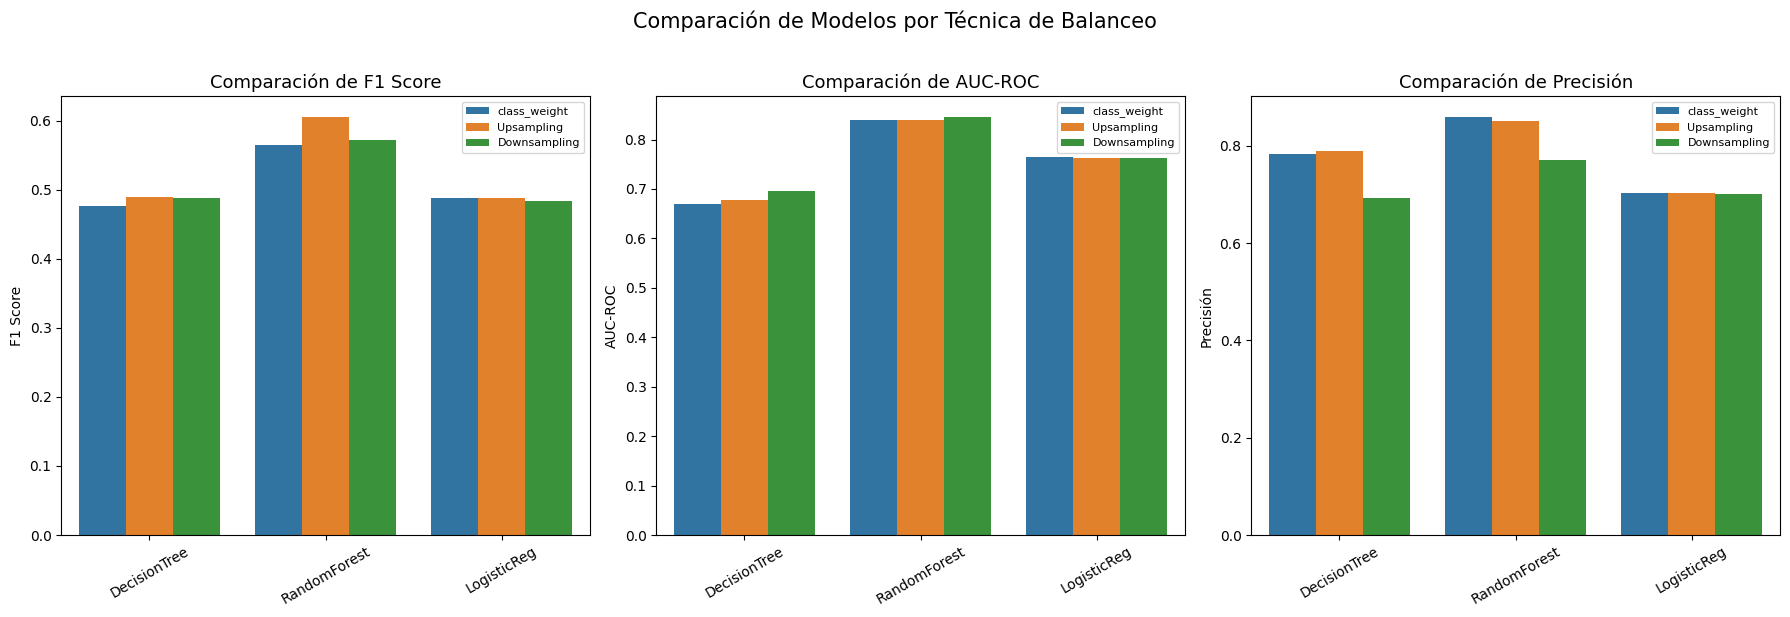

In [23]:

#Gráfico de visualizacion de tabla comparativa de las metricas anteriores por medio de gráficos
print("=== GRÁFICOS DE COMPARACIÓN DE MODELOS ===")
resultados['Modelo_Tecnica'] = resultados['Modelo'] + '\n' + resultados['Técnica']
resultados['Modelo'] = resultados['Modelo'].str.replace('Classifier', '').str.replace('Regression', 'Reg')


fig, axes = plt.subplots(1, 3, figsize=(18, 6))

metricas = ['F1 Score', 'AUC-ROC', 'Precisión']
for i, metrica in enumerate(metricas):
    sns.barplot(ax=axes[i], x='Modelo', y=metrica, hue='Técnica', data=resultados)
    axes[i].set_title(f'Comparación de {metrica}', fontsize=13)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].legend(fontsize=8)

plt.suptitle('Comparación de Modelos por Técnica de Balanceo', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()


=== GRÁFICOS DE COMPARACIÓN DE MODELOS ===


AUC-ROC                             F1 Score             \
Técnica      Downsampling Upsampling class_weight Downsampling Upsampling   
Modelo                                                                      
DecisionTree     0.695363   0.677399     0.668890     0.487886   0.490338   
LogisticReg      0.762217   0.763616     0.763678     0.484065   0.488851   
RandomForest     0.845105   0.838948     0.838707     0.572491   0.605263   

                             Precisión                          
Técnica      class_weight Downsampling Upsampling class_weight  
Modelo                                                          
DecisionTree     0.476534       0.6935      0.789       0.7825  
LogisticReg      0.488851       0.7005      0.702       0.7020  
RandomForest     0.565284       0.7700      0.850       0.8585

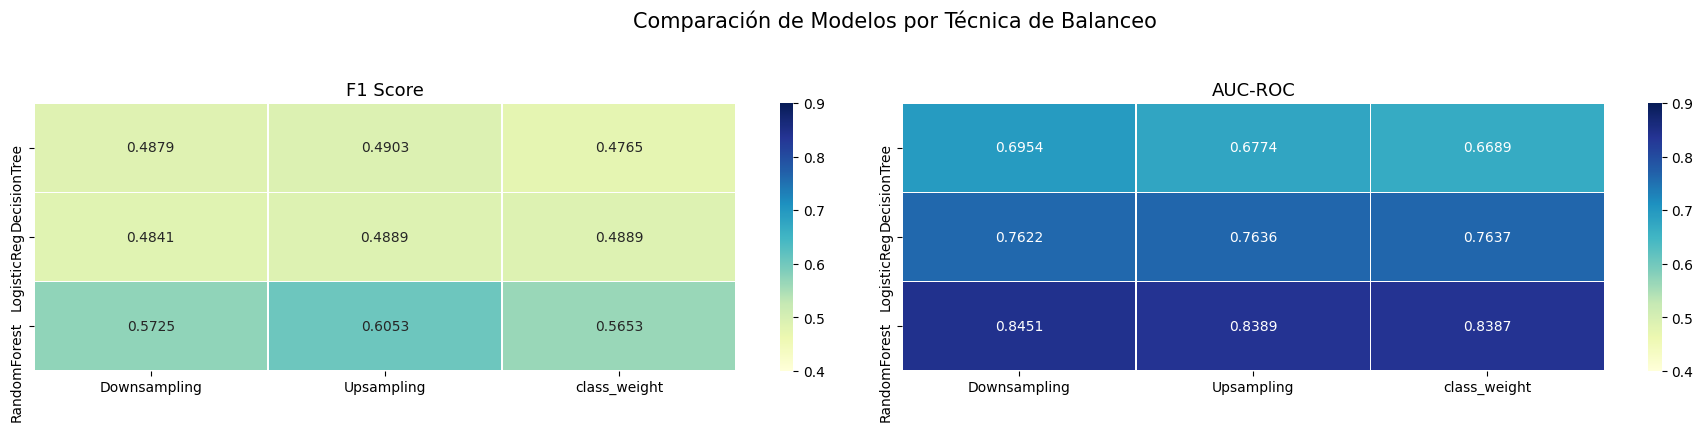

In [24]:

#Gráfico de visualizacion de tabla comparativa de las metricas anteriores por medio de gráficos
print("=== GRÁFICOS DE COMPARACIÓN DE MODELOS ===")
resultados['Modelo_Tecnica'] = resultados['Modelo'] + '\n' + resultados['Técnica']
resultados['Modelo'] = resultados['Modelo'].str.replace('Classifier', '').str.replace('Regression', 'Reg')

#Tabla dinámica con las 3 métricas 
resultados_pivot = resultados.pivot_table(index='Modelo', columns='Técnica', values=['F1 Score', 'AUC-ROC', 'Precisión'])
display(resultados_pivot)

#Heat map F1 Score - AUC-ROC
fig, axes = plt.subplots(1, 2, figsize=(18, 4))

metricas = ['F1 Score', 'AUC-ROC']
for i, metrica in enumerate(metricas):
    pivot = resultados.pivot_table(index='Modelo', columns='Técnica', values=metrica)
    sns.heatmap(pivot, ax=axes[i], annot=True, fmt='.4f', cmap='YlGnBu',
                linewidths=0.5, vmin=0.4, vmax=0.9)
    axes[i].set_title(f'{metrica}', fontsize=13)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

plt.suptitle('Comparación de Modelos por Técnica de Balanceo', fontsize=15, y=1.05)
plt.tight_layout()
plt.show()


### Modelo seleccionado
Despues de haber realizado una comparación minuciosa de las métricas obtenidas, que podemos visualizar en los gráficos anteriores, el modelo seleccionado es **Random Forest Classifier** entrenado con **Upsampling** (sobremuestreo), ya que es el único que supera el umbral mínimo requerido de F1 = 0.59.

+ **Métrica**: *F1 Score* **Valor:** *0.60*


### 3.4 Conclusiones

En este paso se evaluaron **3 algoritmos** (Decision Tree, Random Forest, 
Logistic Regression) con **3 técnicas de balanceo** (class_weight, 
Upsampling, Downsampling), dando un total de 9 combinaciones.

**Hallazgos principales:**
- El algoritmo con mejor desempeño general fue **Random Forest Classifier**, en las 3 técnicas. 
- La técnica de balanceo más efectiva fue **upsampling** en cuanto al umbral F1, ya que solo **1** combinación superaró el umbral mínimo de F1 = 0.59.
- El modelo con el peor desempeño fue Decision Tree, también en las 3 técnicas, pero la técnica menos efectiva para este modelo fue class weight.

**Modelo seleccionado para prueba final:** Random Forest Classifier con Técnica upsampling, con F1 = 0.6052 y AUC-ROC = 0.8389.
Aunque el Random Forest Classifier con técnica downsampling tiene un valor ligeramente más alto (0.8451), con ésta técnica no se supera a F= 0.59, que es nuestra métrica más importante porque ésta combina la precisión y recall. La precisión nos indicaría la cantidad de clientes que realmente se fueron de todos los clientes que el modelo predijo que se irían, y el recall, indica cuantos clientes detectó el modelo detectó de todos los clientes que en ralidad si se fueron. 

En el contexto del banco, el error más costoso es **no detectar a un cliente que sí se va a ir** (falso negativo). Si el modelo lo falla, el banco pierde ese cliente sin poder actuar. Por eso el "Recall" importa mucho, y F1 lo captura. 

## Paso 4: Prueba Final

Este paso consiste en evaluar el modelo seleccionado Random Forest Classifier con Técnica de Sobre muestreo, utilizando el conjunto de datos de prueba para comprobar que el modelo funciona bien con estos datos que todavía no conoce. Vamos a realizar la prueba con las métricas del valor F1, para validar que también supere el umbral mínimo requerido y AUC-ROC para validar qué tambien distingue ambas entre clientes que se van y los que se quedan.

### 4.1 Evaluación del mejor modelo en el conjunto de prueba

In [25]:
# Evaluación de modelo Random Forest Classifier con técnica de sobremuestreo en conjunto de prueba

# Llamamos al modelo entrenado en paso 3.2.2 para que haga predicciones en conjunto de prueba
predictions_test_upsampled_rf = model_upsampled_rf.predict(features_test)

### 4.2 Métrica F1

In [26]:
#Métrica F1
print("=== Predicciones en el conjunto de prueba Métrica F1===")
rf_f1_test = f1_score(target_test, predictions_test_upsampled_rf)
print(f"F1 Score (RF, Up): {rf_f1_test:.4f}")

=== Predicciones en el conjunto de prueba Métrica F1===
F1 Score (RF, Up): 0.5927


### 4.3 Métrica AUC-ROC

In [27]:
#Métrica AUC-ROC
print("=== Predicciones en el conjunto de prueba Métrica AUC-ROC===")
rf_auc_test = roc_auc_score(target_test, model_upsampled_rf.predict_proba(features_test)[:,1])
print(f"AUC-ROC (RF, Up): {rf_auc_test:.4f}")

=== Predicciones en el conjunto de prueba Métrica AUC-ROC===
AUC-ROC (RF, Up): 0.8459


In [28]:
print("=== RESULTADOS FINALES — Random Forest + Upsampling ===")
print(f"{'Métrica':<15} {'Validación':>12} {'Prueba':>12} {'Umbral':>10}")
print("-" * 52)
print(f"{'F1 Score':<15} {rf_f1_up:>12.4f} {rf_f1_test:>12.4f} {'>= 0.59':>10}")
print(f"{'AUC-ROC':<15} {rf_auc_up:>12.4f} {rf_auc_test:>12.4f} {'—':>10}")

=== RESULTADOS FINALES — Random Forest + Upsampling ===
Métrica           Validación       Prueba     Umbral
----------------------------------------------------
F1 Score              0.6053       0.5927    >= 0.59
AUC-ROC               0.8389       0.8459          —


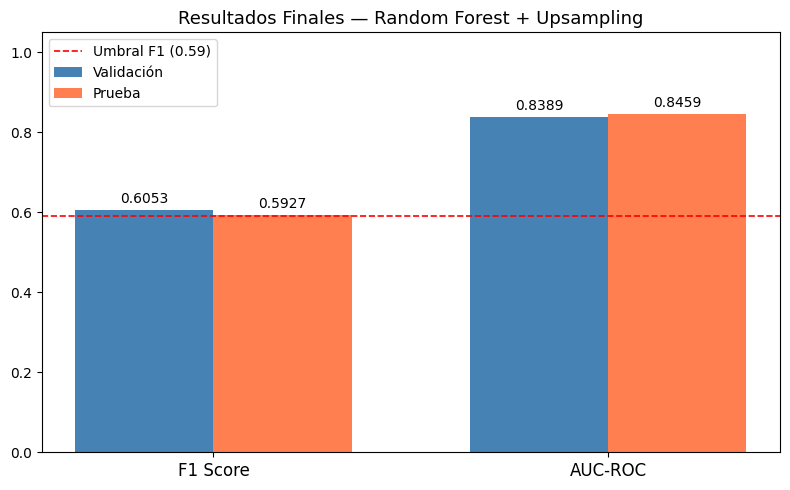

In [29]:

#Gráfico de visualización

fig, ax = plt.subplots(figsize=(8, 5))

metricas = ['F1 Score', 'AUC-ROC']
valores_valid = [rf_f1_up, rf_auc_up]
valores_test = [rf_f1_test, rf_auc_test]

x = range(len(metricas))
width = 0.35

bars1 = ax.bar([i - width/2 for i in x], valores_valid, width, label='Validación', color='steelblue')
bars2 = ax.bar([i + width/2 for i in x], valores_test, width, label='Prueba', color='coral')

ax.axhline(y=0.59, color='red', linestyle='--', linewidth=1.2, label='Umbral F1 (0.59)')

for bar in bars1 + bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=10)

ax.set_xticks(list(x))
ax.set_xticklabels(metricas, fontsize=12)
ax.set_ylim(0, 1.05)
ax.set_title('Resultados Finales — Random Forest + Upsampling', fontsize=13)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()


### Interpretación de resultado en prueba final

El resultado obtenido de la métrica F1 en la prueba final fue:

- **F1 Prueba**: 0.5927

La diferencia es de apenas 0.0126, respecto a **F1 Validación**: 0.6053,  y se debe a que el modelo entrenado funciona con los datos de validación ligeramente mejor que con los nuevos datos de prueba pero en una proporción mínima. Sin embargo el umbral mínimo sigue cumpliéndolo  (F1 ≥ 0.59).

Por el otro lado, la métrica AUC-ROC arrojó el siguiente resultado:

- **AUC-ROC Prueba**: 0.8459

La diferencia es de sólo 0.007 respecto a **AUC-ROC Validación**: 0.8389, lo cual significa que el modelo distingue bien las clases y esto no depende del umbral F1.

En general, nuestro modelo final generaliza bien, es decir no está sobreajustado, es confiable porque se comporta de manera consistente en datos nuevos y además cumple con el umbral mínimo requerido. 

### 4.4 Conclusiones finales


**Resumen del Objetivo del proyecto**

El objetivo del proyecto era desarrollar un modelo con valor F1 mínimo de 0.59, que pueda predecir si un cliente abandonará el banco pronto. Para ello se hicieron pruebas de distintos algoritmos, hasta encontrar el adecuado.

**Hallazgos del preprocesamiento**

- **Columnas con información irrelevante**: Se eliminaron columnas del DataFrame Original que no contenían información útil a la predicción que queriamos realizar.
- **Valores nulos**: Los valores nulos se presentaron únicamente en la columna `Tenure`, los cuales fueron reemplazados con la mediana de los valores no nulos de dicha columna.
- **Codificación**: Las columnas categóricas fueron procesadas con OneHotEncoder para que el modelo pudiera interpretarlas.  
- **Escalado**: Debido a que originalmente las variables numéricas tenían diferencia en sus escalas, se estandarizaron mediante StandardScaler para que tuvieran la misma escala para que el modelo no se desestabilizara.
  
**Hallazgos del análisis de clases**
  Con un data set desbalanceado en proporción 79.63-20.37 el modelo base no fue óptimo debido a ese desequilibrio, por lo que fue necesario mejorar el modelo mediante las técnicas 'class_weight', 'upsampling' (sobremuestreo) y 'downsampling' (submuestreo).
  
**Comparación de técnicas de balanceo**

Se compararon 3 modelos con 3 técnicas cada uno, dando un total de 9 modelos de los cuales el único que superó el umbral mínimo de F1 ≥ 0.59 fue Random Forest Classifier con sobremuestreo y su resultado fue de F1 = 0.6053.

**Resultado del modelo final**

El modelo Random Forest Classifier obtuvo un F1 = 0.5927, superó también el umbral minimo requerido de F1 ≥ 0.59.

**Conclusión general** 

El modelo es confiable y útil para el banco porque cumple el umbral mínimo requerido de F1 ≥ 0.59, generaliza bien en datos nuevos y de acuerdo a su valor AUC-ROC = 0.8459, tiene una alta capacidad de distinguir entre clientes que se van y clientes que se quedan, lo cual le permite al banco actuar a tiempo para retener a sus clientes en riesgo. 